<a href="https://colab.research.google.com/github/yantariel/GP_ML_HW/blob/main/Seminar_1_HW_done.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнее задание к семинару 1

Загрузим наш датасет:

In [ ]:
!wget https://raw.githubusercontent.com/HSE-LAMBDA/MLDM-2022/main/01-intro/train.csv

--2026-09-30 20:20:09--  https://raw.githubusercontent.com/HSE-LAMBDA/MLDM-2022/main/01-intro/train.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 60302 (59K) [text/plain]
Saving to: ‘train.csv.1’

train.csv.1         100%[===================>]  58.89K  --.-KB/s    in 0.03s   

2026-09-30 20:20:09 (1.94 MB/s) - ‘train.csv.1’ saved [60302/60302]



In [ ]:
import pandas as pd
data = pd.read_csv("train.csv", index_col='PassengerId')
data.head(10)  # если цифры не писать в скобки, по умолчанию 5 строк

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S


#### О данных
Это данные о пассажирах «Титаника». Некоторые из столбцов:
* Name — полное имя пассажира.
* Survived — 1, если пассажир выжил после кораблекрушения, 0 в противном случае.
* Pclass — класс пассажира: Pclass == 3 — самый дешёвый, Pclass == 1 — самый дорогой.
* Sex — пол пассажира.
* Age — возраст в годах (если известен).
* SibSp — количество братьев, сестёр и супругов на борту.
* Parch — количество родителей и детей на борту.
* Fare — стоимость билета.
* Embarked — порт посадки:
  * C = Шербур; Q = Куинстаун; S = Саутгемптон.

## Задание 1

In [ ]:
# Вычислите долю выживших для каждого из трёх классов пассажиров (`Pclass` = 1, 2 и 3)

# (получится ли сделать это с помощью groupby?)

print('Доля выживших в 1 классе:', data[data['Pclass'] == 1]['Survived'].mean())  # смотрим только на те строки, в которых класс пассажира = 1
print('Доля выживших во 2 классе:', data[data['Pclass'] == 2]['Survived'].mean())
print('Доля выживших в 3 классе:', data[data['Pclass'] == 3]['Survived'].mean())

# с groupby:
print('-----')
print('Доля выживших для каждого класса:\n', data.groupby('Pclass')['Survived'].mean())  # groupby разбил таблицу на 3 группы по рпинадлежности к классу пассажира

Доля выживших в 1 классе: 0.6296296296296297
Доля выживших во 2 классе: 0.47282608695652173
Доля выживших в 3 классе: 0.24236252545824846
-----
Доля выживших для каждого класса:
 Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


## Задание 2

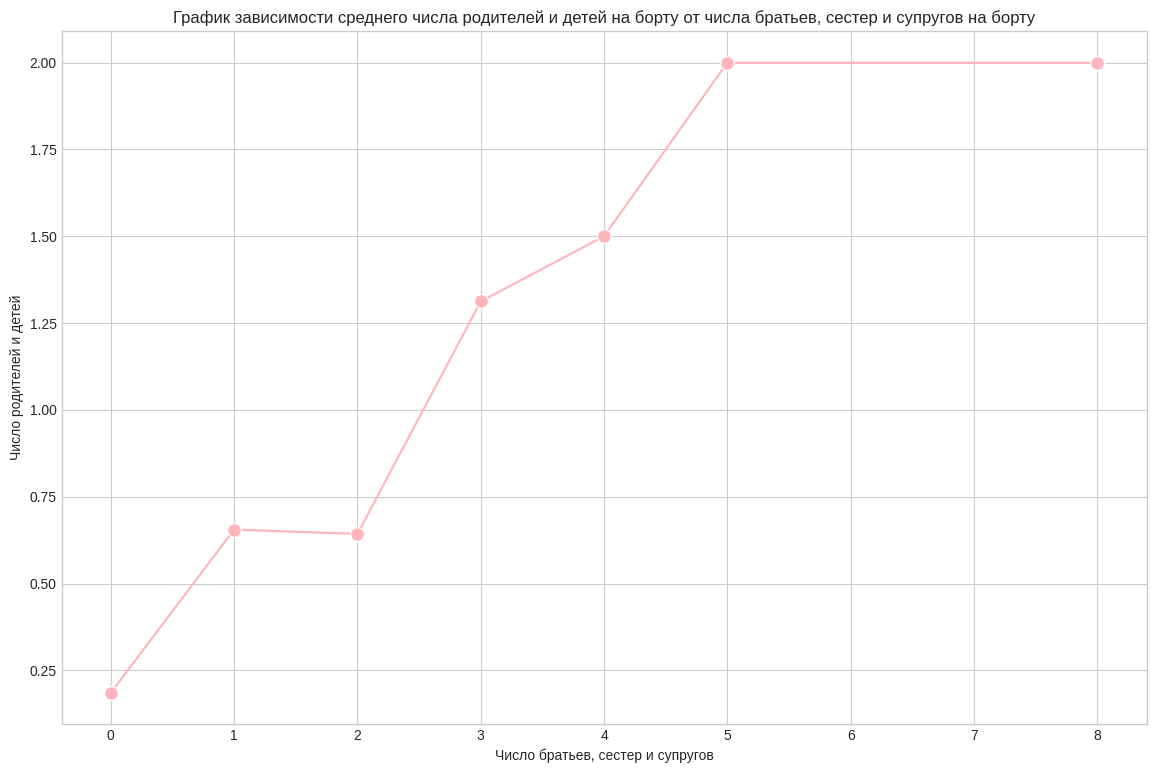

In [ ]:
# Постройте график среднего числа родителей и детей на борту (`Parch`) в зависимости
# от числа братьев, сестёр и супругов на борту (`SibSp`)

import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')  # стиль холста с разметкой

fig, ax = plt.subplots(figsize=(14, 9))  # создаем фигуру для графика, 14 на 9 дюймов

avg_parch = data.groupby('SibSp')['Parch'].mean()  # делает табличку где 1й столбец 1я строка - люди, у которых 0 SinSP, 1й столбец 2я строка- у которых 1 SipSp и тд,
                                                   # во 2м столбце в строках результаты среднего значения Parch в зависимости от SibSp
#print(avg_parch)  # avg_parch.index - 1й столбец, avg_parch.values - 2й стобец

ax.plot(avg_parch.index, avg_parch.values,
        'o-', color='#FFB3BA', markersize=10, markeredgecolor='white', markeredgewidth=1)

ax.set_title('График зависимости среднего числа родителей и детей на борту от числа братьев, сестер и супругов на борту')  # заголовок графика
ax.set_xlabel('Число братьев, сестер и супругов')  # подпись по оси x
ax.set_ylabel('Число родителей и детей')  # подпись по оси y

plt.show()  # показываем график

## Задание 3

Качество проверяется **кросс-валидацией**: данные делятся на 5 частей (фолдов), модель 5 раз обучается на четырёх частях и оценивается на оставшейся. Итоговая оценка — средняя accuracy по фолдам. Так результат не зависит от одного удачного или неудачного разбиения, и модель нельзя «подогнать» под фиксированную тестовую выборку.

*Подсказка:* пропуски в `Age` нужно чем-то заполнить, а категориальный признак `Sex` — превратить в число. Не забудьте, что KNN чувствителен к масштабу признаков.

In [ ]:
# Постройте модель на основе KNeighborsClassifier со средней accuracy
# не ниже 0.80 на 5-кратной кросс-валидации

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

def feature_selection_and_preprocessing(dataset):

  features = dataset[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch']].copy()  # на будущее можно построить графики зависимостей на каждый параметр
                                                                         # или матрицу корелляций, чтобы видеть, что влияет

  features['Sex'] = features['Sex'].map({'female': 1, 'male': 0})  # кодируем значения стобца со словами в циферки
  features['Age'] = features['Age'].fillna(value=data['Age'].mean())  # заменили пропуски в Age на среднее
                                                                      # с помощью data.describe() в строке count можно посмотреть кол-во непропущенных значений в столбце
                                                                      # (тут не совпадает с числом столбцов для Age, значит пропущенные значения есть
  scaler = StandardScaler()  # нормализация, StandardScaler преобразует каждый признак по формуле: (x - среднее) / стандартное отклонение
  scaled_features = scaler.fit_transform(features)

  return scaled_features

x = feature_selection_and_preprocessing(data)
y = data['Survived']

model = KNeighborsClassifier(
    n_neighbors=5
)


# Код проверки (не изменяйте)
from sklearn.model_selection import StratifiedKFold, cross_val_score

data = pd.read_csv("train.csv", index_col='PassengerId')
scores = cross_val_score(
    model,
    feature_selection_and_preprocessing(data.drop('Survived', axis=1)),
    data['Survived'],
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='accuracy',
)
print("Accuracy на фолдах:", scores.round(3))
print(f"Средняя accuracy: {scores.mean():.3f}")
assert scores.mean() >= 0.80, "Нужна средняя accuracy не ниже 0.80"

Accuracy на фолдах: [0.816 0.809 0.792 0.787 0.82 ]
Средняя accuracy: 0.805


## Задание 4

Проверьте, насколько устойчива оценка качества на одном разбиении. Сделайте 50 случайных разбиений train/test (`test_size=100`, разные `random_state`), для каждого обучите модель из задания 3 и посчитайте accuracy на тестовой части.

Постройте гистограмму полученных значений и отметьте на ней вертикальной линией среднюю accuracy на кросс-валидации из задания 3. Насколько сильно может отличаться accuracy на одной случайной тестовой выборке из 100 объектов?

*Подсказка: воспользуйтесь функцией `sklearn.model_selection.train_test_split`.*

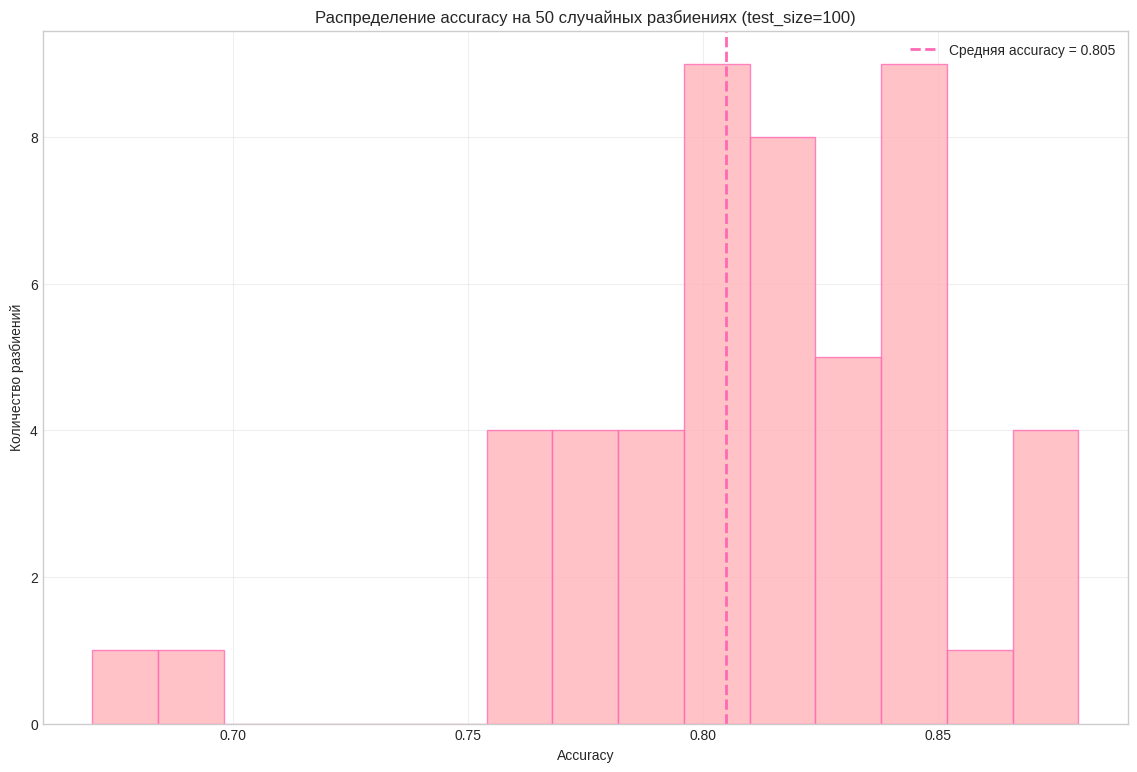

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import numpy as np

accuracies = []
for seed in range(50):
  X_train, X_test, y_train, y_test = train_test_split( x, y, test_size=100, random_state=seed)  # делим дату на train и test

  model.fit(X_train,  y_train)  # обучаем модельку из задания 3 на train

  test_predictions = model.predict(X_test)  # делаем предсказание
  accuracy = accuracy_score(y_test, test_predictions)
  accuracies.append(accuracy)

accuracies = np.array(accuracies)

fig, ax = plt.subplots(figsize=(14, 9))
ax.hist(accuracies, bins=15, color='#FFB3BA', edgecolor='#FF69B4', alpha=0.8)

av_acc_mean = 0.805 # средняя accuracy на кросс-валидации из задания 3
ax.axvline(av_acc_mean, color='#FF69B4', linestyle='--', linewidth=2,
           label=f'Средняя accuracy = {av_acc_mean}')

ax.set_title('Распределение accuracy на 50 случайных разбиениях (test_size=100)')
ax.set_xlabel('Accuracy')
ax.set_ylabel('Количество разбиений')
ax.legend()
ax.grid(alpha=0.3)

plt.show()
